1. **Introduction**

This dataset contains physical measurements and habitat details for 344 penguins collected from three islands in the Palmer Archipelago, Antarctica.

Our Questions to Explore:

1. What are the key physical differences between the 3 penguin species (Adelie, Chinstrap, Gentoo)?

2. Does body mass differ significantly between male and female penguins?

3. Which physical feature (bill length, bill depth, flipper length, or body mass) is most strongly correlated with body mass?

4. Do penguins on Biscoe island weigh more on average than penguins on Dream island?

2. **Load**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

try:
    df = pd.read_csv("penguins.csv")
except FileNotFoundError:
    sns.load_dataset("penguins").to_csv("penguins.csv", index=False)
    df = pd.read_csv("penguins.csv")
    

3. **Inspect**


In [5]:
df = df.rename(columns={"sex": "gender"})

print("Shape:", df.shape)
df.info()
print(df.describe().round(1))
print("Missing values:\n", df.isna().sum())
print(df["species"].value_counts())

Shape: (344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   gender             333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       355

4. **Clean**



In [6]:
df = df.dropna(subset=["bill_length_mm", "body_mass_g"])


df["bill_length_mm"] = df["bill_length_mm"].fillna(df["bill_length_mm"].median())
df["bill_depth_mm"] = df["bill_depth_mm"].fillna(df["bill_depth_mm"].median())
df["flipper_length_mm"] = df["flipper_length_mm"].fillna(df["flipper_length_mm"].median())
df["body_mass_g"] = df["body_mass_g"].fillna(df["body_mass_g"].median())
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])


df["body_mass_kg"] = df["body_mass_g"] / 1000
df["size_group"] = np.where(df["body_mass_g"] < 4000, "Small", "Large")
df["is_male"] = np.where(df["gender"] == "Male", 1, 0)

print("Shape after cleaning:", df.shape)
print("Remaining missing values:\n", df.isna().sum())

Shape after cleaning: (342, 10)
Remaining missing values:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
gender               0
body_mass_kg         0
size_group           0
is_male              0
dtype: int64


5. **Explore (Distributions, Outliers, and Relations)**

 Distribution (Histogram & Count Plot)

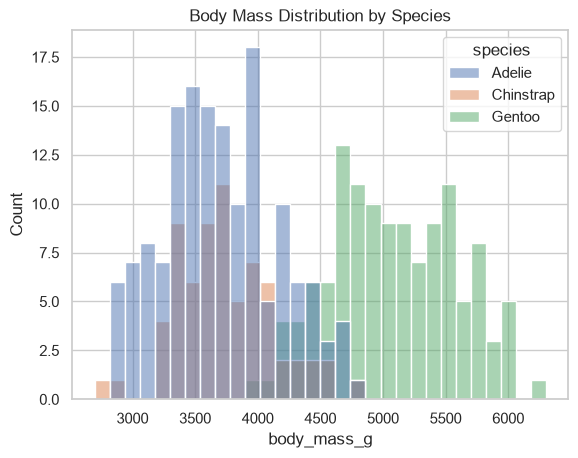

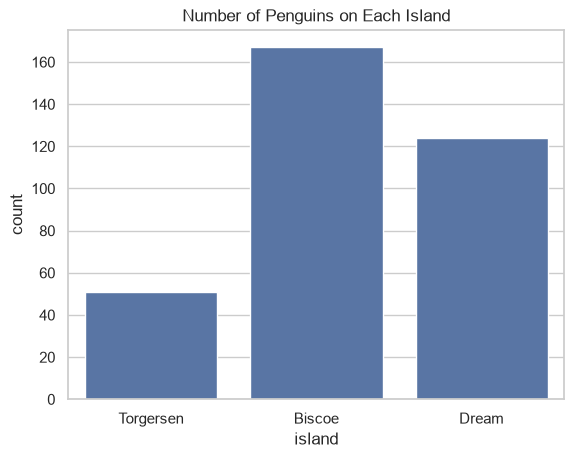

In [7]:
sns.histplot(data=df, x="body_mass_g", bins=30, hue="species")
plt.title("Body Mass Distribution by Species")
plt.show()

sns.countplot(data=df, x="island")
plt.title("Number of Penguins on Each Island")
plt.show()

Outliers (IQR Rule on Body Mass)

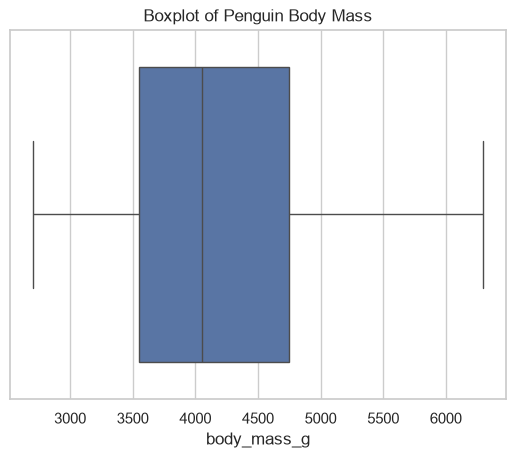

Q1: 3550.0  Q3: 4750.0  IQR: 1200.0
Upper fence: 6550.0
Number of outliers: 0


In [8]:
sns.boxplot(data=df, x="body_mass_g")
plt.title("Boxplot of Penguin Body Mass")
plt.show()

q1 = df["body_mass_g"].quantile(0.25)
q3 = df["body_mass_g"].quantile(0.75)
iqr = q3 - q1
high = q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", round(iqr, 1))
print("Upper fence:", round(high, 1))
outliers = df[df["body_mass_g"] > high]
print("Number of outliers:", len(outliers))

Relations (Correlation Heatmap)

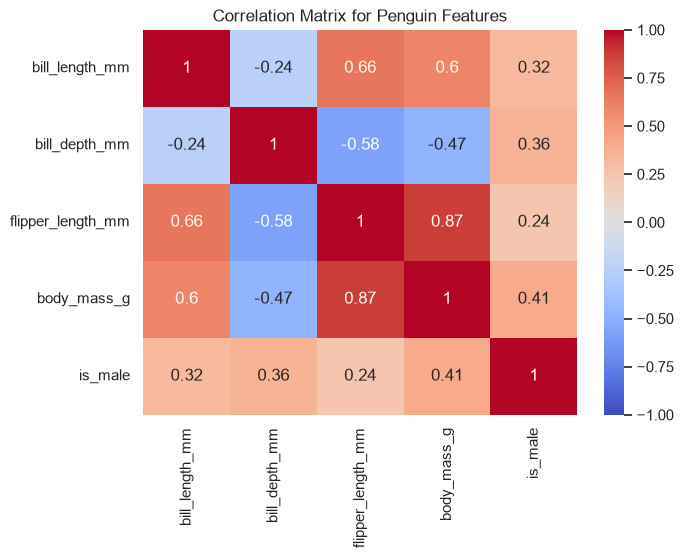

In [9]:
cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "is_male"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix for Penguin Features")
plt.show()

6. Findings



In [10]:
print(df.groupby("species")["body_mass_g"].mean().round(1))

species
Adelie       3700.7
Chinstrap    3733.1
Gentoo       5076.0
Name: body_mass_g, dtype: float64


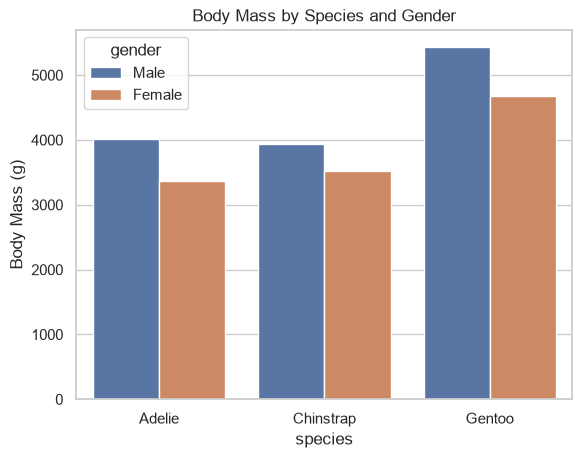

In [11]:
sns.barplot(data=df, x="species", y="body_mass_g", hue="gender", errorbar=None)
plt.title("Body Mass by Species and Gender")
plt.ylabel("Body Mass (g)")
plt.savefig("mass_by_species_and_sex.png", dpi=150, bbox_inches="tight")
plt.show()

6. **Conclusion**

Summary Answers: Gentoo penguins are the largest species by body mass and flipper length. Male penguins consistently outweigh females across all categories. Furthermore, physical traits like flipper length serve as extremely reliable indicators for overall body size and mass.